# 言語モデルのどの層で次のトークンの予測が固まるかを見る（logit lens と tuned lens）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/09_lm_analysis/logit_lens.ipynb)

NLP クックブック 09-07 ／ 言語モデルの確率と内部を調べる

> GPU ランタイム推奨（ランタイム → ランタイムのタイプを変更 → T4 GPU）

デコーダの言語モデルが「日本の首都は」の次に「東京」を出すとき、その予測は何層目で現れるのかを知りたい。各層の隠れ状態に最終層の正規化と出力層をそのまま当てて読む logit lens と、層ごとに小さな変換を学習してから読む tuned lens で、層ごとの予測を図にする。

In [1]:
!pip install -q tuned-lens nnsight datasets sentencepiece matplotlib-fontja

In [2]:
import random
import numpy as np
import sentencepiece as spm
import torch
from huggingface_hub import hf_hub_download
from tokenizers import models
from transformers import AutoModelForCausalLM, AutoTokenizer

random.seed(0); np.random.seed(0); torch.manual_seed(0)

# SB Intuitions の Sarashina2.2-0.5B（指示チューニング前のベースモデル。MIT ライセンス）
name = "sbintuitions/sarashina2.2-0.5b"
tokenizer = AutoTokenizer.from_pretrained(name)
# transformers 5 系は、このモデルの SentencePiece (Unigram) を BPE に変換してしまい、学習時と違う分割になる。
# 元の tokenizer.model から語彙とスコアを読み、分割の方式だけを Unigram に戻す（特殊トークンやチャットテンプレートはそのまま）
sp = spm.SentencePieceProcessor(model_file=hf_hub_download(name, "tokenizer.model"))
tokenizer.backend_tokenizer.model = models.Unigram(
    [(sp.id_to_piece(i), sp.get_score(i)) for i in range(sp.get_piece_size())], unk_id=sp.unk_id(), byte_fallback=True)

BF16 = torch.cuda.get_device_capability()[0] >= 8      # bfloat16 は Ampere (A100, L4) 以降。T4 では float16 を使う
model = AutoModelForCausalLM.from_pretrained(name, dtype=torch.bfloat16 if BF16 else torch.float16, device_map="auto").eval()
n_layers = model.config.num_hidden_layers
print(n_layers, "層", model.model.norm, model.lm_head)

def encode(prompt):
    return tokenizer(tokenizer.bos_token + prompt, add_special_tokens=False, return_tensors="pt")["input_ids"].to(model.device)

@torch.no_grad()
def logit_lens(prompt):
    """各層の隠れ状態を、最終層の正規化 (RMSNorm) と出力層に通したロジット。形は（層 0〜24、位置、語彙数）で、層 0 は埋め込み"""
    ids = encode(prompt)
    out = model(ids, output_hidden_states=True)
    hs = torch.stack(out.hidden_states[:-1])[:, 0]         # 層 0〜23。最後の要素（層 24）は正規化済みなので除く
    logits = model.lm_head(model.model.norm(hs))
    return torch.cat([logits, out.logits]).float(), ids[0]  # 層 24 はモデル本来の出力

def show_top(logits, k=3):
    probs = logits[:, -1].softmax(-1)
    for l, p in enumerate(probs):
        top = p.topk(k)
        print(f"層 {l:2}  " + "  ".join(f"{tokenizer.decode(i)!r}:{v:.2f}" for v, i in zip(top.values.tolist(), top.indices.tolist())))

with torch.no_grad():
    out = model(encode("日本の首都は"), output_hidden_states=True)
print(len(out.hidden_states), "個の隠れ状態。最後の 1 個に出力層だけを当てるとモデルの出力と一致:",
      torch.allclose(model.lm_head(out.hidden_states[-1]).float(), out.logits.float(), atol=1e-2))
logits, ids = logit_lens("日本の首都は")
print([tokenizer.decode(i) for i in ids])
show_top(logits)

24 層 LlamaRMSNorm((1280,), eps=1e-05) Linear(in_features=1280, out_features=102400, bias=False)
25 個の隠れ状態。最後の 1 個に出力層だけを当てるとモデルの出力と一致: True
['<s>', '日本の', '首都', 'は']
層  0  'は':1.00  'の':0.00  'も':0.00
層  1  'は':0.94  '、':0.03  ' ':0.03
層  2  ' ':0.40  'は':0.26  '、':0.19
層  3  'は':0.84  '、':0.15  ' ':0.00
層  4  'は':0.77  '、':0.22  '\u3000':0.00
層  5  '、':0.48  'は':0.41  '\u3000':0.01
層  6  '、':0.48  'は':0.31  ' ':0.02
層  7  '、':0.59  'は':0.10  ' ':0.06
層  8  '、':0.73  'は':0.08  ' ':0.02
層  9  '、':0.65  'は':0.05  ' ':0.04
層 10  '、':0.52  'は':0.06  'land':0.03
層 11  '、':0.58  '都市':0.05  '，':0.04
層 12  '、':0.53  ' ':0.11  '，':0.04
層 13  '、':0.55  ' ':0.05  '，':0.04
層 14  '、':0.53  ' ':0.05  '\u3000':0.04
層 15  '、':0.51  ' ':0.08  '\u3000':0.04
層 16  '、':0.47  '？':0.06  ' ':0.06
層 17  '、':0.34  '？':0.11  '「':0.05
層 18  '、':0.39  ' ':0.14  '？':0.09
層 19  '、':0.27  '？':0.26  '?':0.09
層 20  '？':0.49  '、':0.13  '東京':0.13
層 21  '？':0.49  '東京':0.21  '?':0.10
層 22  '？':0.45  '東京':0.22  '、':0.10
層 

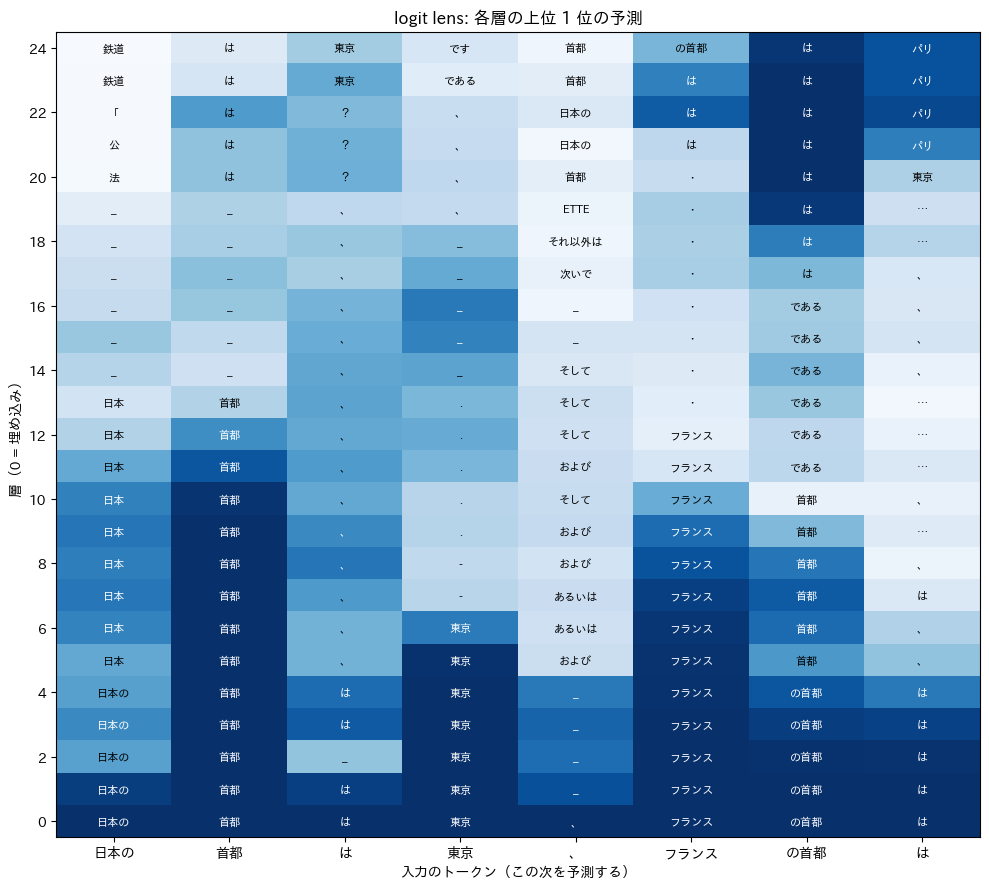

In [3]:
import matplotlib.pyplot as plt
import matplotlib_fontja  # import するだけで日本語のフォントが使える

# 位置ごと・層ごとの上位 1 位の予測（色はその確率）。各位置の予測は「その次のトークン」。図の「_」は空白
prompt = "日本の首都は東京、フランスの首都は"
logits, ids = logit_lens(prompt)
probs = logits[:, 1:].softmax(-1)                          # 先頭の BOS の位置は除く
top_p, top_i = probs.max(-1)
tokens = [tokenizer.decode(i) for i in ids[1:]]
fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(top_p.cpu(), cmap="Blues", vmin=0, vmax=1, aspect="auto", origin="lower")
for l in range(top_i.shape[0]):
    for j in range(top_i.shape[1]):
        ax.text(j, l, tokenizer.decode(top_i[l, j]).replace("\n", "\\n").replace(" ", "_").replace("\u3000", "_")[:5], ha="center", va="center", fontsize=8,
                color="white" if top_p[l, j] > 0.6 else "black")
ax.set_xticks(range(len(tokens)), tokens); ax.set_xlabel("入力のトークン（この次を予測する）")
ax.set_yticks(range(0, n_layers + 1, 2)); ax.set_ylabel("層（0 = 埋め込み）")
ax.set_title("logit lens: 各層の上位 1 位の予測")
plt.tight_layout(); plt.show()

事実 '日本の首都は'                     → '東京'     最終層の確率 0.36  初めて 1 位になる層 23  順位（層 0, 6, 12, 18, 24）: [441, 325, 60, 64, 1]
事実 'ドイツの首都は'                    → 'ベルリン'   最終層の確率 0.41  初めて 1 位になる層 24  順位（層 0, 6, 12, 18, 24）: [5876, 6285, 3344, 2423, 1]
事実 '日本で一番高い山は'                  → '富士山'    最終層の確率 0.33  初めて 1 位になる層 22  順位（層 0, 6, 12, 18, 24）: [4225, 1308, 1485, 30, 1]
翻訳 '「りんご」は英語で「'                 → 'apple'  最終層の確率 0.82  初めて 1 位になる層 20  順位（層 0, 6, 12, 18, 24）: [31273, 53753, 7070, 326, 1]
翻訳 '英語の「dog」は日本語で「'             → '犬'      最終層の確率 0.63  初めて 1 位になる層 19  順位（層 0, 6, 12, 18, 24）: [937, 45927, 59275, 30, 1]
翻訳 '犬 → dog\n猫 → cat\n水 →'      → ' water' 最終層の確率 0.91  初めて 1 位になる層 21  順位（層 0, 6, 12, 18, 24）: [50509, 13225, 2408, 55, 1]
計算 '2+3=5\n4+4=8\n3+4='         → '7'      最終層の確率 0.97  初めて 1 位になる層 23  順位（層 0, 6, 12, 18, 24）: [121, 239, 44, 11, 1]
計算 '26+15='                     → '4'      最終層の確率 0.63  初めて 1 位になる層 23  順位（層 0, 6, 12, 18, 24）: [86, 523, 18, 6, 1]
続き '太陽は東から昇り、西に'              

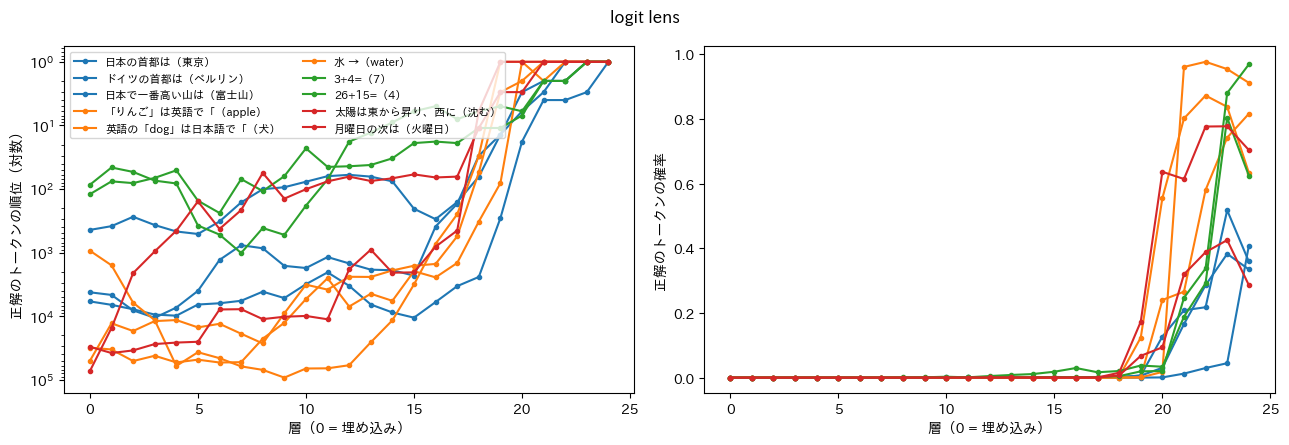

In [4]:
# 事実の想起・翻訳・計算・言葉の続きの例で、正解のトークンの層ごとの順位と確率を見る
examples = [
    ("事実", "日本の首都は", "東京"), ("事実", "ドイツの首都は", "ベルリン"), ("事実", "日本で一番高い山は", "富士山"),
    ("翻訳", "「りんご」は英語で「", "apple"), ("翻訳", "英語の「dog」は日本語で「", "犬"), ("翻訳", "犬 → dog\n猫 → cat\n水 →", " water"),
    ("計算", "2+3=5\n4+4=8\n3+4=", "7"), ("計算", "26+15=", "4"),          # 26+15=41 の最初の桁
    ("続き", "太陽は東から昇り、西に", "沈む"), ("続き", "月曜日の次は", "火曜日"),
]

def target_id(target):
    ids = tokenizer(target, add_special_tokens=False)["input_ids"]
    assert len(ids) == 1, (target, ids)                    # 1 トークンの語だけを正解にする
    return ids[0]

def rank_prob(logits, tid):
    """最後の位置での正解トークンの順位（1 = 1 位）と確率を層ごとに"""
    last = logits[:, -1]
    return (last > last[:, [tid]]).sum(-1).add(1).cpu().numpy(), last.softmax(-1)[:, tid].cpu().numpy()

ll = {}
for cat, prompt, target in examples:
    ll[prompt] = rank_prob(logit_lens(prompt)[0], target_id(target))
    r, p = ll[prompt]
    first = int(np.argmax(r == 1)) if (r == 1).any() else None
    print(f"{cat} {prompt!r:28} → {target!r:8} 最終層の確率 {p[-1]:.2f}  初めて 1 位になる層 {first}  順位（層 0, 6, 12, 18, 24）: {r[[0, 6, 12, 18, 24]].tolist()}")

colors = {"事実": "tab:blue", "翻訳": "tab:orange", "計算": "tab:green", "続き": "tab:red"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for cat, prompt, target in examples:
    r, p = ll[prompt]
    label = f"{prompt.splitlines()[-1]}（{target.strip()}）"
    axes[0].plot(r, color=colors[cat], marker=".", label=label); axes[1].plot(p, color=colors[cat], marker=".")
axes[0].set_yscale("log"); axes[0].invert_yaxis(); axes[0].set_ylabel("正解のトークンの順位（対数）")
axes[1].set_ylabel("正解のトークンの確率")
for ax in axes: ax.set_xlabel("層（0 = 埋め込み）")
axes[0].legend(fontsize=8, ncol=2); fig.suptitle("logit lens")
plt.tight_layout(); plt.show()

In [5]:
# nnsight（NDIF のライブラリ）でも同じことが書ける。各層のモジュールの出力を取り出したり書き換えたりできる
import nnsight
from nnsight import TransformersModel

lm = TransformersModel(model, tokenizer=tokenizer)        # 読み込み済みのモデルをそのまま包む
with lm.trace(tokenizer.bos_token + "日本の首都は"):
    preds = nnsight.save([])
    for layer in lm.model.layers:                          # transformers 5 では、各層の出力は隠れ状態のテンソル
        preds.append(lm.lm_head(lm.model.norm(layer.output))[0, -1].argmax().save())
nn_top1 = [tokenizer.decode(int(i)) for i in preds]
lens_top1 = [tokenizer.decode(int(i)) for i in logit_lens("日本の首都は")[0][1:, -1].argmax(-1)]
print("nnsight の層 1〜24 の 1 位:", nn_top1)
print("hidden_states と一致した層の数:", sum(a == b for a, b in zip(nn_top1, lens_top1)), "/", n_layers)

nnsight の層 1〜24 の 1 位: ['は', ' ', 'は', 'は', '、', '、', '、', '、', '、', '、', '、', '、', '、', '、', '、', '、', '、', '、', '、', '？', '？', '？', '東京', '東京']
hidden_states と一致した層の数: 24 / 24


In [6]:
import time
import warnings
import torch.nn.functional as F
from datasets import load_dataset
from tuned_lens.nn.lenses import TunedLens

# tuned lens の学習データ: 日本語版 Wikipedia（wikimedia/wikipedia の 20231101.ja。本文は CC BY-SA 3.0 と GFDL）の先頭の記事を
# 256 トークンずつに切る（長い記事に偏らないよう 1 記事から最大 4 個）。記事の 20 本に 1 本は評価用に分ける
wiki = load_dataset("wikimedia/wikipedia", "20231101.ja", split="train", streaming=True)
L, train, val = 256, [], []
for i, article in enumerate(wiki):
    ids = tokenizer(article["text"], add_special_tokens=False)["input_ids"]
    chunks = [[tokenizer.bos_token_id] + ids[s:s + L - 1] for s in range(0, len(ids) - L + 2, L - 1)][:4]
    (val if i % 20 == 0 else train).extend(chunks)
    if len(train) >= 1200 and len(val) >= 50:
        break
train, val = torch.tensor(train), torch.tensor(val[:50])
print("学習", tuple(train.shape), "評価", tuple(val.shape), f"（{i + 1} 記事）")

# 層ごとの「平行移動つきの線形変換」(translator) を、最終層の出力分布との KL ダイバージェンスが小さくなるように学習する。
# 変換は恒等写像から始まり、モデル本体と最終層の正規化・出力層は固定
lens = TunedLens.from_model(model).float().to(model.device)
params = [p for p in lens.parameters() if p.requires_grad]
print(f"translator のパラメータ {sum(p.numel() for p in params) / 1e6:.1f}M（{len(lens)} 層分）")
steps, batch_size = 100, 4
opt = torch.optim.AdamW(params, lr=1e-3, weight_decay=1e-3)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1, (s + 1) / 20) * (1 - s / steps))   # 20 ステップのウォームアップ後に線形に減衰
amp_dtype = torch.bfloat16 if BF16 else torch.float16
scaler = torch.amp.GradScaler(enabled=not BF16)            # float16 のときは勾配のアンダーフローを防ぐ
# GradScaler が最初のステップを飛ばすと出る「scheduler の呼び出し順」の警告は、ここでは無害なので表示しない
warnings.filterwarnings("ignore", message="Detected call of `lr_scheduler.step")

def lens_kl(o, l, lens_fn):
    """層 l の隠れ状態をレンズで読んだ分布と、最終層の分布との KL ダイバージェンス（トークンあたり、nat）"""
    with torch.autocast("cuda", dtype=amp_dtype):
        logp = F.log_softmax(lens_fn(o.hidden_states[l].float()).float(), -1)
    return F.kl_div(logp, F.log_softmax(o.logits.float(), -1), log_target=True, reduction="none").sum(-1).mean()

g = torch.Generator().manual_seed(0)
t0 = time.time()
# T4 で 3〜5 分ほど（目安）
for step in range(steps):
    x = train[torch.randint(len(train), (batch_size,), generator=g)].to(model.device)
    with torch.no_grad():
        o = model(x, output_hidden_states=True)
    total = 0.0
    for l in range(n_layers):                              # 層ごとに backward してメモリを抑える（translator は層ごとに独立）
        loss = lens_kl(o, l, lambda h: lens(h, l))
        scaler.scale(loss).backward(); total += loss.item()
    scaler.step(opt); scaler.update(); opt.zero_grad(); sched.step()
    if step % 20 == 0 or step == steps - 1:
        print(f"step {step:3}  平均 KL {total / n_layers:.3f}  {time.time() - t0:.0f} 秒")
print(f"GPU メモリの最大 {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

学習 (1202, 256) 評価 (50, 256) （370 記事）
translator のパラメータ 39.4M（24 層分）
step   0  平均 KL 11.607  2 秒
step  20  平均 KL 6.889  43 秒
step  40  平均 KL 3.286  84 秒
step  60  平均 KL 2.939  121 秒
step  80  平均 KL 2.839  159 秒
step  99  平均 KL 2.633  192 秒
GPU メモリの最大 5.6 GB


logit lens 73.5 37.3 28.0 22.4 18.2 15.0 12.5 10.5 9.0 8.0 7.3 6.8 6.3 5.9 5.5 5.1 4.6 3.9 3.3 2.7 1.9 1.1 0.6 0.3
tuned lens 11.6 6.6 5.5 4.9 4.5 4.1 3.7 3.4 3.1 2.9 2.7 2.6 2.5 2.3 2.2 2.1 1.8 1.6 1.4 1.1 0.8 0.5 0.3 0.2


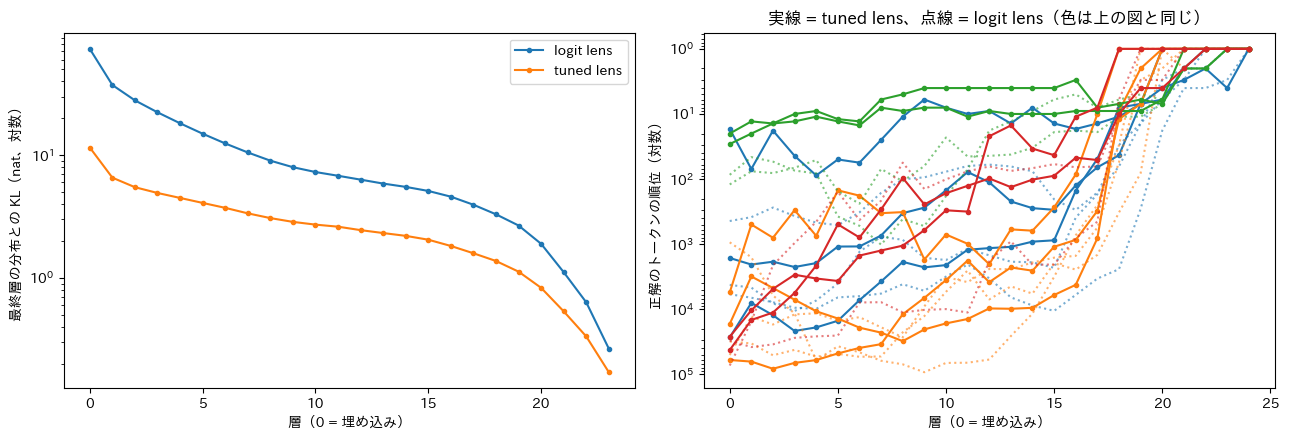

事実 '東京'     初めて 1 位になる層  logit lens 23  tuned lens 20   層 12 の順位  logit lens 60  tuned lens 9
事実 'ベルリン'   初めて 1 位になる層  logit lens 24  tuned lens 24   層 12 の順位  logit lens 3344  tuned lens 112
事実 '富士山'    初めて 1 位になる層  logit lens 22  tuned lens 22   層 12 の順位  logit lens 1485  tuned lens 1151
翻訳 'apple'  初めて 1 位になる層  logit lens 20  tuned lens 20   層 12 の順位  logit lens 7070  tuned lens 3835
翻訳 '犬'      初めて 1 位になる層  logit lens 19  tuned lens 18   層 12 の順位  logit lens 59275  tuned lens 2031
翻訳 ' water' 初めて 1 位になる層  logit lens 21  tuned lens 20   層 12 の順位  logit lens 2408  tuned lens 9720
計算 '7'      初めて 1 位になる層  logit lens 23  tuned lens 21   層 12 の順位  logit lens 44  tuned lens 9
計算 '4'      初めて 1 位になる層  logit lens 23  tuned lens 23   層 12 の順位  logit lens 18  tuned lens 4
続き '沈む'     初めて 1 位になる層  logit lens 19  tuned lens 18   層 12 の順位  logit lens 1836  tuned lens 22
続き '火曜日'    初めて 1 位になる層  logit lens 21  tuned lens 22   層 12 の順位  logit lens 64  tuned lens 98
層  0  '、':0.31  '「':0.07  '『':0

In [7]:
# 評価用の記事で、層ごとに「最終層の分布との KL」を logit lens と tuned lens で比べる
kl = {"logit lens": np.zeros(n_layers), "tuned lens": np.zeros(n_layers)}
with torch.no_grad():
    for b in range(0, len(val), batch_size):
        o = model(val[b:b + batch_size].to(model.device), output_hidden_states=True)
        for l in range(n_layers):
            kl["logit lens"][l] += lens_kl(o, l, lens.unembed).item() * len(val[b:b + batch_size]) / len(val)
            kl["tuned lens"][l] += lens_kl(o, l, lambda h: lens(h, l)).item() * len(val[b:b + batch_size]) / len(val)
for k, v in kl.items():
    print(f"{k:10}", " ".join(f"{x:.1f}" for x in v))

@torch.no_grad()
def tuned_lens(prompt):
    ids = encode(prompt)
    out = model(ids, output_hidden_states=True)
    logits = [lens(out.hidden_states[l][0].float(), l) for l in range(n_layers)]
    return torch.cat([torch.stack(logits), out.logits.float()]), ids[0]

tl = {prompt: rank_prob(tuned_lens(prompt)[0], target_id(target)) for _, prompt, target in examples}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for k, v in kl.items():
    axes[0].plot(v, marker=".", label=k)
axes[0].set_yscale("log"); axes[0].set_xlabel("層（0 = 埋め込み）"); axes[0].set_ylabel("最終層の分布との KL（nat、対数）"); axes[0].legend()
for cat, prompt, target in examples:
    axes[1].plot(ll[prompt][0], color=colors[cat], ls=":", alpha=0.6)
    axes[1].plot(tl[prompt][0], color=colors[cat], marker=".")
axes[1].set_yscale("log"); axes[1].invert_yaxis(); axes[1].set_xlabel("層（0 = 埋め込み）"); axes[1].set_ylabel("正解のトークンの順位（対数）")
axes[1].set_title("実線 = tuned lens、点線 = logit lens（色は上の図と同じ）")
plt.tight_layout(); plt.show()

for cat, prompt, target in examples:
    first = {k: (int(np.argmax(d[prompt][0] == 1)) if (d[prompt][0] == 1).any() else None) for k, d in [("logit", ll), ("tuned", tl)]}
    print(f"{cat} {target!r:8} 初めて 1 位になる層  logit lens {first['logit']}  tuned lens {first['tuned']}   "
          f"層 12 の順位  logit lens {ll[prompt][0][12]}  tuned lens {tl[prompt][0][12]}")
show_top(tuned_lens("日本の首都は")[0])

- logit lens (nostalgebraist, 2020) は、途中の層の隠れ状態を「最終層の手前にあるもの」とみなして、最終層の正規化と出力層 (unembedding) をそのまま当てて読む。学習は要らない。`output_hidden_states=True` で得られる 25 個（埋め込み + 24 層）のうち、transformers の Llama 系では最後の 1 個が最終層の正規化を通した後の値なので（出力の `True` のとおり）、正規化を 2 回かけないよう層 24 はモデルの出力をそのまま使っている。正解はどれも 1 トークンの語にしてある（「26+15=」は答え 41 の最初の桁の「4」）。
- この実行では、10 例とも正解のトークンが 1 位になったのは層 19〜24 で、確率は層 18 まではほぼ 0 だった。ヒートマップでは、前半の層は入力のトークン自身が 1 位になりやすく（「首都」の位置では層 13 まで「首都」、「東京」の位置では層 6 まで「東京」）、中間の層は「、」や空白（図の「_」）、「である」などのありふれたトークンが多い。「日本の首都は東京、フランスの首都は」の最後の位置では、層 20 で文脈に出てきた「東京」が 1 位になり、層 21 から「パリ」に変わった。
- 素朴な logit lens の限界: 途中の層の隠れ状態が最終層と同じ「座標系」にあるとは限らない。評価用の記事で最終層の分布との KL ダイバージェンスを測ると、層 0 で 73.5、層 12 で 6.3 nat と大きく、前半の層はほとんど読めていない。読めないことは情報がないことを意味しない。Belrose ら (2023) は、BLOOM や OPT では logit lens がもっともらしい予測を取り出せず、多くの層で入力のトークンが 1 位になること、特定の語彙に偏ることを報告している。
- tuned lens（Belrose ら, 2023）は、層ごとに平行移動つきの線形変換 (translator) を、最終層の分布との KL が小さくなるように学習してから読む。ここでは tuned-lens ライブラリ（MIT ライセンス）の `TunedLens` を使い、仕組みが見えるよう学習のループは自分で書いた。学習は 100 ステップ × 4 × 256 トークン（約 10 万トークン）で、論文の初期の設定（SGD、250 ステップ × 2^18 トークン）よりずっと少ない（論文の最新版は、最適化手法を Muon にすると KL がずっと下がるとして Muon を勧めている）。それでも評価用の記事での KL は層 0 で 73.5 → 11.6、層 12 で 6.3 → 2.5 に下がり、「日本の首都は」の前半の層で入力のトークン「は」が 1 位になる現象は消えた。
- 一方、正解が初めて 1 位になる層は、tuned lens でも 10 例中 5 例で 1〜3 層早まっただけで（4 例は同じ、「火曜日」は 1 層遅い）、層 12 での正解の順位が上がったのは 10 例中 8 例だった。例が 10 個、学習が短く 1 回だけの結果なので、「どの層で答えが決まるか」の細かい違いは言えない。ライブラリが公開している学習済みのレンズは GPT-2 や EleutherAI、Meta などの英語中心のモデル向けで、日本語のモデルは自分で学習する。
- この章の「BERT の各層に品詞や構文の情報がどれくらい入っているかを調べる（プロービング）」は、外部のラベル（品詞など）を予測する分類器を層ごとに学習する。logit lens はモデル自身の出力層で語彙の空間に読み出すもので学習が要らず、tuned lens はその中間（目標をモデル自身の最終出力にした線形のプローブ）にあたる。どれも「その層から読み出せる」ことを示すだけで、モデルがその層の情報を使っているかは分からない。確かめるには、層の出力を書き換える介入の実験をする。
- nnsight（Fiotto-Kaufman ら, 2024。MIT ライセンス）は、そのような介入にも使えるライブラリで、`layer.output` を読むだけでなく書き換えることもできる。nnsight 0.8 では `LanguageModel` は非推奨で `TransformersModel` を使う。transformers 5 では層の出力がテンソルなので、古い資料の `layer.output[0]` は不要になる。
- モデルは SB Intuitions の Sarashina2.2-0.5B（MIT ライセンス。日本語・英語・コードのウェブのデータなど 10 兆トークンで学習したベースモデル）、tuned lens の学習データは日本語版 Wikipedia（CC BY-SA 3.0 と GFDL）。トークナイザーの修正は、大規模言語モデルの章の「オープンな LLM とチャットする（チャットテンプレート）」の注意書きを参照。T4 と同じ float16 の経路で実行し、GPU メモリの最大は 5.6 GB だった。